<a href="https://colab.research.google.com/github/IdeaDP/vggt-frame-selection/blob/main/VGGT_Frame_Selection_Start.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VGGT frame-selection study — first working reconstruction
Goal: determine whether selecting six sharp, visually diverse frames improves reconstruction over uniform and random selection.

This is an inference-only starter, not a validated new method. VGGT is the pretrained baseline (CVPR 2025), not our contribution.

## Before running
1. Open this notebook in Google Colab and select **Runtime → Change runtime type → GPU**. GPU availability varies.
2. Record a 15–25 second video of a static textured object or small desk scene. Move the phone slowly around it while keeping overlapping views. Keep the object still. Avoid glass, mirrors and a plain white object.
3. Run the cells in order. Start with uniform selection and six frames. If CUDA runs out of memory, use four frames for **all** compared methods and restart the runtime.

Today succeeds when you can view and download one coloured reconstruction. Quantitative accuracy requires reference geometry or camera poses, added in the next stage.

Sources: [official code](https://github.com/facebookresearch/vggt), [paper](https://openaccess.thecvf.com/content/CVPR2025/html/Wang_VGGT_Visual_Geometry_Grounded_Transformer_CVPR_2025_paper.html).


In [22]:
import subprocess, sys
from pathlib import Path
repo = Path('/content/vggt')
if not repo.exists():
    subprocess.run(['git', 'clone', 'https://github.com/facebookresearch/vggt.git', str(repo)], check=True)

# Print requirements to inspect compatibility
req_path = repo / 'requirements.txt'
if req_path.exists():
    print("--- Contents of requirements.txt ---")
    print(req_path.read_text())
    print("------------------------------------\n")

try:
    # Run pip install without quiet flag to see output and errors directly in Colab console
    print("Attempting dependency installation...")
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-r', str(req_path), 'opencv-python-headless', 'plotly'], check=True)
except subprocess.CalledProcessError as e:
    print("\n[ERROR] Pip installation failed. See the output above for which package caused the compile/resolution failure.")
    raise e

sys.path.insert(0, str(repo))
print('VGGT commit:', subprocess.check_output(['git','-C',str(repo),'rev-parse','HEAD'], text=True).strip())

--- Contents of requirements.txt ---
torch==2.3.1
torchvision==0.18.1
numpy==1.26.1
Pillow
huggingface_hub
einops
safetensors

------------------------------------

Attempting dependency installation...

[ERROR] Pip installation failed. See the output above for which package caused the compile/resolution failure.


CalledProcessError: Command '['/usr/bin/python3', '-m', 'pip', 'install', '-r', '/content/vggt/requirements.txt', 'opencv-python-headless', 'plotly']' returned non-zero exit status 1.

In [23]:
import subprocess, sys
from pathlib import Path
print('Python:', sys.version)
repo = Path('/content/vggt')
if not (repo / 'vggt' / 'models' / 'vggt.py').is_file():
    if repo.exists():
        raise RuntimeError('An incomplete /content/vggt directory exists. Rename it, then retry.')
    subprocess.run(['git', 'clone', 'https://github.com/facebookresearch/vggt.git', str(repo)], check=True)
# Keep Colab's matched torch/torchvision installation. Avoid old upstream pins.
try:
    import torch, torchvision
except Exception as exc:
    raise RuntimeError('Colab torch/torchvision cannot import. Use a fresh GPU runtime and send this error.') from exc
subprocess.run([sys.executable, '-m', 'pip', 'install',
                'Pillow', 'huggingface_hub', 'einops', 'safetensors',
                'opencv-python-headless', 'plotly', 'matplotlib'], check=True)
sys.path.insert(0, str(repo))
from vggt.models.vggt import VGGT
print('Torch:', torch.__version__, 'Torchvision:', torchvision.__version__)
print('CUDA available:', torch.cuda.is_available())
print('VGGT commit:', subprocess.check_output(['git','-C',str(repo),'rev-parse','HEAD'], text=True).strip())
print('Setup imports passed')


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Torch: 2.11.0+cu130 Torchvision: 0.26.0+cu130
CUDA available: True
VGGT commit: a288dd0f14786c93483e45524328726ab7b1b4ce
Setup imports passed


In [24]:
import torch, cv2, numpy as np, json, time, gc, shutil
import matplotlib.pyplot as plt
from google.colab import files
assert torch.cuda.is_available(), 'Select a GPU runtime before continuing.'
print('GPU:', torch.cuda.get_device_name(0))
print('VRAM GB:', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))
work = Path('/content/frame_selection_project')
work.mkdir(exist_ok=True)


GPU: Tesla T4
VRAM GB: 14.56


## Upload your video
Upload one MP4/MOV video. It is processed in your Colab session. Save the final outputs before the session expires.

In [25]:
uploaded = files.upload()
if len(uploaded) != 1:
    raise ValueError('Upload exactly one video.')
video_path = Path(next(iter(uploaded)))
del uploaded


Saving kitchen.mp4 to kitchen.mp4


## Extract a shared candidate pool
All methods select from these same candidates. Frames are resized for storage; official VGGT preprocessing is applied later. Re-running overwrites numbered candidate JPEGs. Use one video per session.

In [26]:
def extract_frames(video, destination, sample_hz=2.0, max_frames=60):
    destination.mkdir(parents=True, exist_ok=True)
    for p in destination.glob('frame_*.jpg'):
        p.unlink()
    cap = cv2.VideoCapture(str(video))
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not cap.isOpened() or not np.isfinite(fps) or fps <= 0:
        cap.release()
        raise ValueError('Cannot read video or frame rate; try an MP4 export.')
    count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if count < 2:
        cap.release()
        raise ValueError('Video has too few frames.')
    target_count = min(max_frames, max(2, int(count / fps * sample_hz)))
    targets = set(np.linspace(0, count-1, target_count, dtype=int).tolist())
    paths, timestamps = [], []
    i = 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if i in targets:
            h,w = frame.shape[:2]
            frame = cv2.resize(frame, (round(w*768/max(h,w)), round(h*768/max(h,w))))
            path = destination / f'frame_{i:06d}.jpg'
            if not cv2.imwrite(str(path), frame):
                raise IOError(f'Could not write {path}')
            paths.append(path)
            timestamps.append(i/fps)
        i += 1
    cap.release()
    if len(paths) < 2:
        raise ValueError('Too few candidate frames decoded.')
    return paths, timestamps

paths, timestamps = extract_frames(video_path, work/'candidates')
print('Candidate frames:', len(paths))


Candidate frames: 25


## Compare three selection methods
**Uniform:** evenly spaced candidate indices. **Random:** fixed seeded sampling. **Sharp + diverse:** discard the blurriest quarter, then greedy farthest-point selection using spatial colour descriptors.

Colour diversity is not camera-baseline diversity: lighting and background can fool it. This deliberately simple baseline is the hypothesis we will test. Keep the score, frame count, preprocessing and seed fixed across scenes; do not tune on your final test scenes.


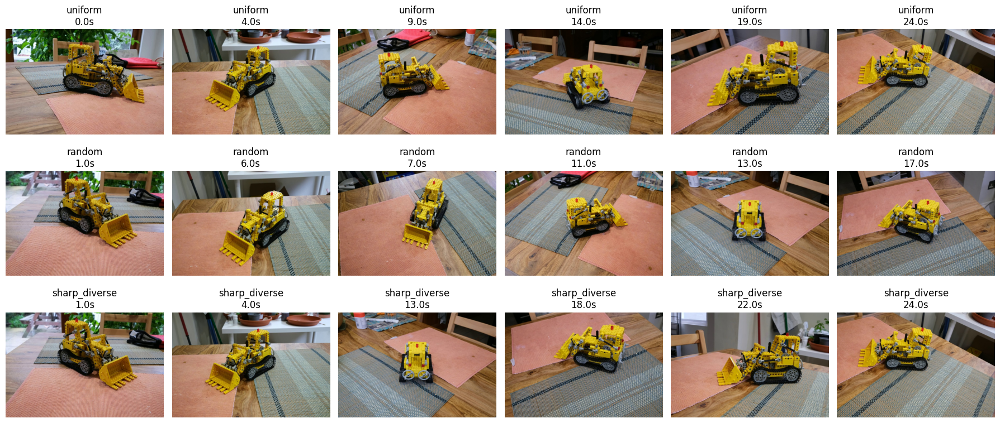

In [50]:
def frame_features(paths):
    sharpness, descriptors = [], []
    for p in paths:
        image = cv2.imread(str(p))
        if image is None:
            raise ValueError(f'Cannot read {p}')
        image = cv2.resize(image, (256,256))
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        sharpness.append(cv2.Laplacian(gray, cv2.CV_64F).var())
        lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
        desc = cv2.resize(lab, (8,8), interpolation=cv2.INTER_AREA).astype(np.float32).ravel()/255.0
        descriptors.append(desc)
    return np.asarray(sharpness), np.stack(descriptors)

def select_indices(method, k, sharpness, descriptors, seed=0):
    n=len(sharpness)
    if not 1 <= k <= n:
        raise ValueError('k must be between 1 and candidate count')
    if method == 'uniform':
        return np.linspace(0,n-1,k,dtype=int).tolist()
    if method == 'random':
        return sorted(np.random.default_rng(seed).choice(n,k,replace=False).tolist())
    if method != 'sharp_diverse':
        raise ValueError('Unknown selection method')
    keep=max(k, int(np.ceil(0.75*n)))
    pool=np.argsort(-sharpness, kind='stable')[:keep]
    chosen=[int(pool[0])]
    while len(chosen)<k:
        dist=((descriptors[pool,None,:]-descriptors[chosen][None,:,:])**2).mean(axis=-1).min(axis=1)
        dist[np.isin(pool,chosen)] = -np.inf
        chosen.append(int(pool[np.argmax(dist)]))
    return sorted(chosen)

K = 6
SEED = 0
assert len(paths)>=K, 'Use a longer video or decrease K.'
sharpness, descriptors = frame_features(paths)
selections = {m:select_indices(m,K,sharpness,descriptors,SEED) for m in ['uniform','random','sharp_diverse']}
fig, axs = plt.subplots(3,K,figsize=(3*K,8),squeeze=False)
for row,(method,indices) in enumerate(selections.items()):
    for col,idx in enumerate(indices):
        axs[row,col].imshow(cv2.cvtColor(cv2.imread(str(paths[idx])),cv2.COLOR_BGR2RGB))
        axs[row,col].set_title(f'{method}\n{timestamps[idx]:.1f}s')
        axs[row,col].axis('off')
plt.tight_layout()
plt.savefig(work/'selected_frames.png',dpi=120)
plt.show()


## Load the pretrained baseline
The first run downloads model weights. This uses the original research checkpoint; consult the official repository for its license. Model setup is outside measured inference time.

In [10]:
from vggt.models.vggt import VGGT
from vggt.utils.load_fn import load_and_preprocess_images
from vggt.utils.pose_enc import pose_encoding_to_extri_intri
from vggt.utils.geometry import unproject_depth_map_to_point_map
device = 'cuda'
dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
model = VGGT.from_pretrained('facebook/VGGT-1B').to(device).eval()
print('Model ready')


config.json:   0%|          | 0.00/62.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 5.03GB            

model.safetensors: downloading bytes:           |  0.00B            

Model ready


## Run one reconstruction
Start with `uniform`. Once it works, change METHOD to `random` and then `sharp_diverse`, and re-run this cell and the viewer cell.

Uses depth and predicted cameras to unproject points, following official usage. Saves raw predictions for later evaluation, a confidence-filtered display cloud, and timings. Confidence is **not** reconstruction accuracy. Display filtering is fixed at the same percentile for all methods but can hide errors; evaluate unfiltered predictions against ground truth later.


In [65]:
METHOD = 'sharp_diverse'
indices = selections[METHOD]
out = work/METHOD
out.mkdir(exist_ok=True)
gc.collect()
torch.cuda.empty_cache()
images = load_and_preprocess_images([str(paths[i]) for i in indices]).to(device)
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()
t0=time.perf_counter()
with torch.inference_mode(), torch.autocast(device_type='cuda',dtype=dtype):
    predictions=model(images)
torch.cuda.synchronize()
elapsed=time.perf_counter()-t0
peak=torch.cuda.max_memory_allocated()/2**30
raw={key:value.float().cpu().numpy() for key,value in predictions.items() if torch.is_tensor(value)}
np.savez_compressed(out/'predictions.npz',**raw)
with torch.inference_mode():
    extrinsic,intrinsic=pose_encoding_to_extri_intri(predictions['pose_enc'].float(),images.shape[-2:])
extrinsic=extrinsic[0].float().cpu().numpy()
intrinsic=intrinsic[0].float().cpu().numpy()
depth=raw['depth'][0]
points=unproject_depth_map_to_point_map(depth,extrinsic,intrinsic)
points=np.asarray(points).reshape(-1,3)
colours=(images.float().cpu().permute(0,2,3,1).numpy().reshape(-1,3)*255).clip(0,255).astype(np.uint8)
confidence=raw['depth_conf'][0].reshape(-1)
valid=np.isfinite(points).all(axis=1)&np.isfinite(confidence)
if not valid.any():
    raise ValueError('No finite reconstructed points.')
threshold=np.percentile(confidence[valid],50)
mask=valid&(confidence>=threshold)
xyz,rgb=points[mask],colours[mask]
np.savez_compressed(out/'cameras.npz',extrinsic=extrinsic,intrinsic=intrinsic)
with (out/'cloud.ply').open('w') as f:
    f.write(f'ply\nformat ascii 1.0\nelement vertex {len(xyz)}\nproperty float x\nproperty float y\nproperty float z\nproperty uchar red\nproperty uchar green\nproperty uchar blue\nend_header\n')
    for p,c in zip(xyz,rgb):
        f.write(f'{p[0]} {p[1]} {p[2]} {int(c[0])} {int(c[1])} {int(c[2])}\n')
commit=subprocess.check_output(['git','-C',str(repo),'rev-parse','HEAD'],text=True).strip()
metrics={'method':METHOD,'k':K,'seed':SEED,'candidate_count':len(paths),'selected_indices':indices,'timestamps_s':[timestamps[i] for i in indices], 'inference_s':elapsed,'peak_allocated_gpu_gb':peak,'gpu':torch.cuda.get_device_name(0),'input_shape':list(images.shape),'vggt_commit':commit,'display_confidence_percentile':50,'accuracy':None}
(out/'run.json').write_text(json.dumps(metrics,indent=2))
print(json.dumps(metrics,indent=2))
del predictions,images,raw
gc.collect()
torch.cuda.empty_cache()


/content/vggt/vggt/models/vggt.py:65: FutureWarning:

`torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.



{
  "method": "sharp_diverse",
  "k": 6,
  "seed": 0,
  "candidate_count": 25,
  "selected_indices": [
    0,
    1,
    9,
    15,
    17,
    23
  ],
  "timestamps_s": [
    0.0,
    0.7999880313873291,
    7.431976079940796,
    12.367998123168945,
    14.036072015762329,
    19.00389289855957
  ],
  "inference_s": 11.23029152900017,
  "peak_allocated_gpu_gb": 10.669223308563232,
  "gpu": "Tesla T4",
  "input_shape": [
    6,
    3,
    392,
    518
  ],
  "vggt_commit": "a288dd0f14786c93483e45524328726ab7b1b4ce",
  "display_confidence_percentile": 50,
  "accuracy": null
}


In [42]:
import plotly.graph_objects as go
sample=np.random.default_rng(0).choice(len(xyz),min(30000,len(xyz)),replace=False)
p,c=xyz[sample],rgb[sample]
fig=go.Figure(go.Scatter3d(x=p[:,0],y=p[:,1],z=p[:,2],mode='markers',marker=dict(size=1,color=[f'rgb({r},{g},{b})' for r,g,b in c])))
fig.update_layout(title=f'{METHOD}: coloured reconstruction (display subset)',scene=dict(aspectmode='data'),height=650)
fig.show()
fig.write_html(str(out/'viewer.html'),include_plotlyjs=True)


In [45]:
import plotly.graph_objects as go
sample=np.random.default_rng(0).choice(len(xyz),min(30000,len(xyz)),replace=False)
p,c=xyz[sample],rgb[sample]
fig=go.Figure(go.Scatter3d(x=p[:,0],y=p[:,1],z=p[:,2],mode='markers',marker=dict(size=1,color=[f'rgb({r},{g},{b})' for r,g,b in c])))
fig.update_layout(title=f'{METHOD}: coloured reconstruction (display subset)',scene=dict(aspectmode='data'),height=650)
fig.show()
fig.write_html(str(out/'viewer.html'),include_plotlyjs=True)


In [66]:
import plotly.graph_objects as go
sample=np.random.default_rng(0).choice(len(xyz),min(30000,len(xyz)),replace=False)
p,c=xyz[sample],rgb[sample]
fig=go.Figure(go.Scatter3d(x=p[:,0],y=p[:,1],z=p[:,2],mode='markers',marker=dict(size=1,color=[f'rgb({r},{g},{b})' for r,g,b in c])))
fig.update_layout(title=f'{METHOD}: coloured reconstruction (display subset)',scene=dict(aspectmode='data'),height=650)
fig.show()
fig.write_html(str(out/'viewer.html'),include_plotlyjs=True)


In [61]:
import plotly.graph_objects as go
sample=np.random.default_rng(0).choice(len(xyz),min(30000,len(xyz)),replace=False)
p,c=xyz[sample],rgb[sample]
fig=go.Figure(go.Scatter3d(x=p[:,0],y=p[:,1],z=p[:,2],mode='markers',marker=dict(size=1,color=[f'rgb({r},{g},{b})' for r,g,b in c])))
fig.update_layout(title=f'{METHOD}: coloured reconstruction (display subset)',scene=dict(aspectmode='data'),height=650)
fig.show()
fig.write_html(str(out/'viewer.html'),include_plotlyjs=True)


## Download your results
Includes candidate images, raw predictions, camera parameters, selection preview, run metadata, PLY clouds and offline HTML viewers. Keep the same candidate pool for all methods.

In [51]:
archive=shutil.make_archive('/content/vggt_second_K=8_results','zip',work)
files.download(archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

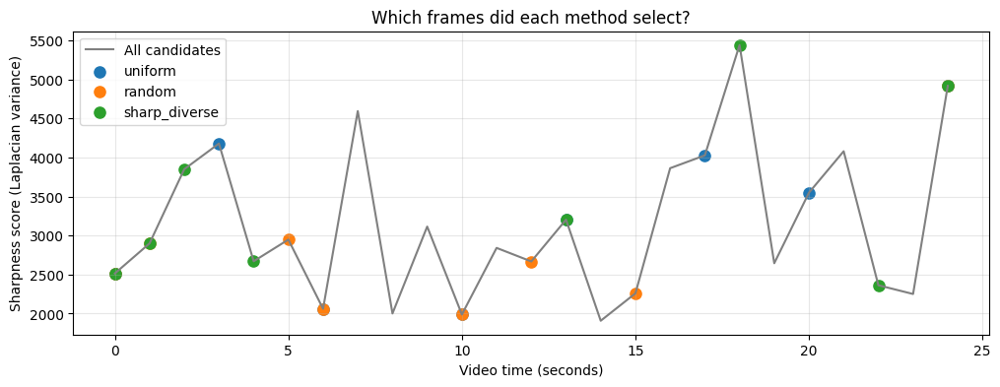

uniform: mean sharpness=3304.92, mean visual distance=0.1031, largest time gap=4.0s
random: mean sharpness=2781.88, mean visual distance=0.1188, largest time gap=9.0s
sharp_diverse: mean sharpness=3482.13, mean visual distance=0.1030, largest time gap=9.0s


In [48]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(timestamps, sharpness, color="gray", label="All candidates")

for method, indices in selections.items():
    ax.scatter(
        np.array(timestamps)[indices],
        sharpness[indices],
        s=65,
        label=method
    )

ax.set_xlabel("Video time (seconds)")
ax.set_ylabel("Sharpness score (Laplacian variance)")
ax.set_title("Which frames did each method select?")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

for method, indices in selections.items():
    times = np.array(timestamps)[indices]
    features = descriptors[indices]

    distances = np.sqrt(
        ((features[:, None] - features[None, :]) ** 2).mean(axis=-1)
    )
    pairs = distances[np.triu_indices(len(indices), k=1)]

    print(
        f"{method}: "
        f"mean sharpness={sharpness[indices].mean():.2f}, "
        f"mean visual distance={pairs.mean():.4f}, "
        f"largest time gap={np.diff(times).max():.1f}s"
    )

In [56]:
print("Current K:", K)
print("Candidate count:", len(paths))

for method, indices in selections.items():
    saved = json.loads((work / method / "run.json").read_text())
    print(
        method,
        "\n  Current selection:", indices,
        "\n  Saved reconstruction:", saved["selected_indices"],
        "\n  Saved K:", saved["k"]
    )

Current K: 6
Candidate count: 25
uniform 
  Current selection: [0, 4, 9, 14, 19, 24] 
  Saved reconstruction: [0, 4, 9, 14, 19, 24] 
  Saved K: 6
random 
  Current selection: [1, 6, 7, 11, 13, 17] 
  Saved reconstruction: [1, 6, 7, 11, 13, 17] 
  Saved K: 6
sharp_diverse 
  Current selection: [1, 4, 13, 18, 22, 24] 
  Saved reconstruction: [1, 4, 13, 18, 22, 24] 
  Saved K: 6


## Next research steps
1. Verify all three methods run on the same video and frame count. Visual comparisons are debugging evidence, not proof of improved accuracy.
2. Add scenes with reference poses or geometry. Choose a documented benchmark split and follow its pose/coordinate conventions. Monocular reconstruction has scale ambiguity: align consistently before computing geometric errors.
3. Compare on a small development set first, then freeze the method and evaluate on held-out scenes. Run random selection with at least five seeds.
4. Report pose error or aligned reconstruction accuracy/completeness, selection overhead, inference time, memory and failure rate. Count every failed reconstruction.
5. Separate model warm-up from repeated timed trials. Current timing is a smoke-test measurement, not a benchmark.
6. Ablate sharpness-only, diversity-only and their combination. Investigate viewpoint-aware descriptors only after this simple baseline is working.

Potential contribution: a reproducible selection policy that improves the quality–cost tradeoff. A negative result is useful if explained and supported by measurements. No novelty or superiority claim is established by this notebook.

If a cell fails, retain its full traceback and GPU name. Dependencies and upstream APIs may change. This notebook has been syntax checked and its selection logic tested; actual VGGT inference has not been run by its author in the current environment.


In [57]:
from pathlib import Path
import subprocess

data_dir = Path("/content/tum_data")
data_dir.mkdir(exist_ok=True)

archive = data_dir / "rgbd_dataset_freiburg1_desk.tgz"

url = (
    "https://cvg.cit.tum.de/rgbd/dataset/freiburg1/"
    "rgbd_dataset_freiburg1_desk.tgz"
)

subprocess.run(
    ["wget", "-c", "--show-progress", "-O", str(archive), url],
    check=True
)

print("Downloaded:", archive)

Downloaded: /content/tum_data/rgbd_dataset_freiburg1_desk.tgz


In [58]:
import tarfile

dataset = data_dir / "rgbd_dataset_freiburg1_desk"

if not dataset.exists():
    with tarfile.open(archive, "r:gz") as tar:
        tar.extractall(data_dir, filter="data")

required = ["rgb", "depth", "rgb.txt", "depth.txt", "groundtruth.txt"]

for name in required:
    path = dataset / name
    print(name, "✓" if path.exists() else "MISSING")

print("RGB images:", len(list((dataset / "rgb").glob("*.png"))))
print("Depth images:", len(list((dataset / "depth").glob("*.png"))))

rgb ✓
depth ✓
rgb.txt ✓
depth.txt ✓
groundtruth.txt ✓
RGB images: 613
Depth images: 595


In [59]:
import json
import numpy as np
from pathlib import Path

def read_timestamp_list(path):
    rows = []
    for line in path.read_text().splitlines():
        line = line.strip()
        if line and not line.startswith("#"):
            timestamp, filename = line.split()[:2]
            rows.append((float(timestamp), filename))
    return sorted(rows)

rgb_rows = read_timestamp_list(dataset / "rgb.txt")
depth_rows = read_timestamp_list(dataset / "depth.txt")
depth_times = np.array([t for t, _ in depth_rows])

# Match each RGB image to its closest depth image.
# Reject matches more than 20 milliseconds apart.
matched = []
for rgb_time, rgb_file in rgb_rows:
    j = int(np.argmin(np.abs(depth_times - rgb_time)))
    difference = abs(depth_times[j] - rgb_time)

    if difference <= 0.020:
        matched.append({
            "rgb_time": rgb_time,
            "rgb_path": str(dataset / rgb_file),
            "depth_time": depth_rows[j][0],
            "depth_path": str(dataset / depth_rows[j][1]),
            "time_difference_s": float(difference)
        })

assert len(matched) >= 25, "Too few timestamp-matched frames."

# Freeze a common candidate pool for every selection method.
candidate_indices = np.linspace(
    0, len(matched) - 1, 25, dtype=int
)
tum_candidates = [matched[i] for i in candidate_indices]

paths = [Path(row["rgb_path"]) for row in tum_candidates]
first_time = tum_candidates[0]["rgb_time"]
timestamps = [
    row["rgb_time"] - first_time for row in tum_candidates
]

assert all(p.exists() for p in paths)
assert all(Path(r["depth_path"]).exists() for r in tum_candidates)

# Separate directory: preserve the kitchen outputs.
work = Path("/content/tum_fr1_desk_project")
work.mkdir(exist_ok=True)
(work / "candidate_manifest.json").write_text(
    json.dumps(tum_candidates, indent=2)
)

K = 6
SEED = 0
sharpness, descriptors = frame_features(paths)
selections = {
    method: select_indices(
        method, K, sharpness, descriptors, SEED
    )
    for method in ["uniform", "random", "sharp_diverse"]
}

print("Matched RGB/depth pairs:", len(matched))
print("Candidate count:", len(paths))
print("Candidate time span:", round(timestamps[-1], 2), "seconds")

for method, indices in selections.items():
    print(method, indices)

Matched RGB/depth pairs: 596
Candidate count: 25
Candidate time span: 19.84 seconds
uniform [0, 4, 9, 14, 19, 24]
random [1, 6, 7, 11, 13, 17]
sharp_diverse [0, 1, 9, 15, 17, 23]


In [67]:
from PIL import Image
import numpy as np
import json

method = "sharp_diverse"
run_dir = work / method

run = json.loads((run_dir / "run.json").read_text())
manifest = json.loads((work / "candidate_manifest.json").read_text())

with np.load(run_dir / "predictions.npz") as saved:
    predicted = saved["depth"][0, ..., 0].astype(np.float64)

n, height, width = predicted.shape
assert n == len(run["selected_indices"])

reference = []

for idx in run["selected_indices"]:
    row = manifest[idx]

    with Image.open(row["rgb_path"]) as rgb:
        original_width, original_height = rgb.size

    # Reproduce the official loader's default resize and crop.
    resized_width = 518
    resized_height = round(
        original_height * resized_width / original_width / 14
    ) * 14

    with Image.open(row["depth_path"]) as depth_image:
        depth_image = depth_image.resize(
            (resized_width, resized_height),
            resample=Image.Resampling.NEAREST
        )
        depth = np.asarray(depth_image, dtype=np.float64) / 5000.0

    if resized_height > 518:
        top = (resized_height - 518) // 2
        depth = depth[top:top + 518]

    assert depth.shape == (height, width), (
        f"Reference {depth.shape} != prediction {(height, width)}"
    )
    reference.append(depth)

reference = np.stack(reference)

reference_valid = np.isfinite(reference) & (reference > 0)
prediction_valid = np.isfinite(predicted) & (predicted > 0)
valid = reference_valid & prediction_valid
assert valid.any(), "No valid depth comparisons."

# One reference-fitted scale for the entire six-view reconstruction.
# This is scale-aligned evaluation, not a metric-scale prediction.
scale = float(np.median(reference[valid] / predicted[valid]))
aligned = predicted * scale

error = aligned[valid] - reference[valid]
abs_rel = float(np.mean(np.abs(error) / reference[valid]))
rmse = float(np.sqrt(np.mean(error ** 2)))
ratio = np.maximum(
    aligned[valid] / reference[valid],
    reference[valid] / aligned[valid]
)
delta1 = float(np.mean(ratio < 1.25))

metrics = {
    "method": method,
    "evaluation": "selected_views_reference_fitted_global_scale",
    "scale": scale,
    "abs_rel": abs_rel,
    "rmse_m": rmse,
    "delta1": delta1,
    "valid_pixel_count": int(valid.sum()),
    "prediction_valid_fraction_on_reference": float(
        valid.sum() / reference_valid.sum()
    )
}

(run_dir / "depth_metrics.json").write_text(
    json.dumps(metrics, indent=2)
)
print(json.dumps(metrics, indent=2))

{
  "method": "sharp_diverse",
  "evaluation": "selected_views_reference_fitted_global_scale",
  "scale": 1.4233355199040603,
  "abs_rel": 0.030036301210126872,
  "rmse_m": 0.13774395423642316,
  "delta1": 0.9853593839914504,
  "valid_pixel_count": 912325,
  "prediction_valid_fraction_on_reference": 1.0
}


In [68]:
import gc
import time

TARGETS = [3, 12, 21]
common_dir = work / "common_targets"
common_dir.mkdir(exist_ok=True)

assert all(
    target not in indices
    for target in TARGETS
    for indices in selections.values()
)

for method, context_indices in selections.items():
    for target in TARGETS:
        output = common_dir / f"{method}_target_{target:02d}.npz"

        # Avoid repeating completed runs if the cell is interrupted.
        if output.exists():
            print("Already saved:", output.name)
            continue

        gc.collect()
        torch.cuda.empty_cache()

        # Put the common target first in every method.
        input_indices = [target] + context_indices
        batch = load_and_preprocess_images(
            [str(paths[i]) for i in input_indices]
        ).to(device)

        torch.cuda.synchronize()
        start = time.perf_counter()

        with torch.inference_mode(), torch.autocast(
            device_type="cuda", dtype=dtype
        ):
            result = model(batch)

        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        target_depth = (
            result["depth"][0, 0, ..., 0]
            .float().cpu().numpy()
        )

        np.savez_compressed(
            output,
            depth=target_depth,
            target_index=target,
            context_indices=np.array(context_indices),
            inference_s=elapsed
        )

        del result, batch
        gc.collect()
        torch.cuda.empty_cache()

        print(method, "target", target, "saved")

/content/vggt/vggt/models/vggt.py:65: FutureWarning:

`torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.



uniform target 3 saved
uniform target 12 saved
uniform target 21 saved
random target 3 saved
random target 12 saved
random target 21 saved
sharp_diverse target 3 saved
sharp_diverse target 12 saved
sharp_diverse target 21 saved


In [74]:
from PIL import Image
import pandas as pd

manifest = json.loads(
    (work / "candidate_manifest.json").read_text()
)

rows = []

methods=["uniform", "random", "sharp_diverse","random_seed1", "random_seed2","random_seed3", "random_seed4" ]
for method in methods:
    for target in TARGETS:
        filename = common_dir / f"{method}_target_{target:02d}.npz"

        with np.load(filename) as saved:
            pred = saved["depth"].astype(np.float64)

        item = manifest[target]

        # Match the default VGGT resize/crop transformation.
        with Image.open(item["rgb_path"]) as image:
            original_w, original_h = image.size

        resized_w = 518
        resized_h = round(
            original_h * resized_w / original_w / 14
        ) * 14

        with Image.open(item["depth_path"]) as image:
            image = image.resize(
                (resized_w, resized_h),
                Image.Resampling.NEAREST
            )
            gt = np.asarray(image, dtype=np.float64) / 5000.0

        if resized_h > 518:
            top = (resized_h - 518) // 2
            gt = gt[top:top + 518]

        assert gt.shape == pred.shape

        reference_valid = np.isfinite(gt) & (gt > 0)
        prediction_valid = np.isfinite(pred) & (pred > 0)
        valid = reference_valid & prediction_valid

        # Same calibration pixel locations for every method.
        yy, xx = np.indices(gt.shape)
        calibration_grid = (yy % 4 == 0) & (xx % 4 == 0)

        calibration = valid & calibration_grid
        evaluation = valid & ~calibration_grid

        assert calibration.any() and evaluation.any()

        scale = float(np.median(gt[calibration] / pred[calibration]))
        aligned = pred[evaluation] * scale
        reference = gt[evaluation]

        error = aligned - reference
        ratio = np.maximum(
            aligned / reference, reference / aligned
        )

        rows.append({
            "method": method,
            "target": target,
            "scale": scale,
            "abs_rel": float(np.mean(np.abs(error) / reference)),
            "rmse_m": float(np.sqrt(np.mean(error ** 2))),
            "delta1": float(np.mean(ratio < 1.25)),
            "evaluated_pixels": int(evaluation.sum()),
            "prediction_valid_fraction": float(
                valid.sum() / reference_valid.sum()
            )
        })

details = pd.DataFrame(rows)
summary = details.groupby("method", sort=False)[
    ["abs_rel", "rmse_m", "delta1"]
].mean()

details.to_csv(common_dir / "depth_metrics_per_target.csv", index=False)
summary.to_csv(common_dir / "depth_metrics_summary.csv")

print("PER-TARGET RESULTS")
print(details.to_string(index=False))

print("\nMEAN RESULTS — each target weighted equally")
print(summary.to_string())

PER-TARGET RESULTS
       method  target    scale  abs_rel   rmse_m   delta1  evaluated_pixels  prediction_valid_fraction
      uniform       3 1.504761 0.022285 0.134940 0.986415            140821                        1.0
      uniform      12 1.488980 0.017433 0.061676 0.984478            150042                        1.0
      uniform      21 1.235405 0.028770 0.085035 0.986122            141091                        1.0
       random       3 1.517901 0.022964 0.128415 0.988844            140821                        1.0
       random      12 1.283476 0.019737 0.073204 0.977933            150042                        1.0
       random      21 1.250677 0.019548 0.069090 0.988816            141091                        1.0
sharp_diverse       3 1.465387 0.023792 0.137792 0.986834            140821                        1.0
sharp_diverse      12 1.462778 0.018068 0.069286 0.981285            150042                        1.0
sharp_diverse      21 1.158437 0.016501 0.071901 0.987

In [71]:
import shutil
from google.colab import files

archive = shutil.make_archive(
    "/content/TUM_desk_K6_results",
    "zip",
    root_dir=str(work)
)

files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [72]:
# Repeated random baselines: seeds 1–4.
# Rejection sampling keeps target images out of the context.
# Seed 0's existing selection already satisfies this condition.

assert K == 6
assert TARGETS == [3, 12, 21]
assert len(paths) == 25

for seed in [1, 2, 3, 4]:
    rng = np.random.default_rng(seed)

    for attempt in range(1000):
        context_indices = sorted(
            rng.choice(len(paths), K, replace=False).tolist()
        )
        if set(context_indices).isdisjoint(TARGETS):
            break
    else:
        raise RuntimeError("Could not select target-free context.")

    method = f"random_seed{seed}"
    print(method, "context:", context_indices)

    (common_dir / f"{method}_selection.json").write_text(
        json.dumps({
            "seed": seed,
            "context_indices": context_indices,
            "targets": TARGETS,
            "sampling": "random; reject sets containing targets"
        }, indent=2)
    )

    for target in TARGETS:
        output = common_dir / f"{method}_target_{target:02d}.npz"

        if output.exists():
            with np.load(output) as saved:
                assert saved["context_indices"].tolist() == context_indices
            print("Already saved:", output.name)
            continue

        gc.collect()
        torch.cuda.empty_cache()

        input_indices = [target] + context_indices
        batch = load_and_preprocess_images(
            [str(paths[i]) for i in input_indices]
        ).to(device)

        torch.cuda.synchronize()
        start = time.perf_counter()

        with torch.inference_mode(), torch.autocast(
            device_type="cuda", dtype=dtype
        ):
            result = model(batch)

        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        target_depth = (
            result["depth"][0, 0, ..., 0]
            .float().cpu().numpy()
        )

        np.savez_compressed(
            output,
            depth=target_depth,
            target_index=target,
            context_indices=np.array(context_indices),
            seed=seed,
            inference_s=elapsed
        )

        del result, batch
        gc.collect()
        torch.cuda.empty_cache()

        print(method, "target", target, "saved")

random_seed1 context: [5, 8, 9, 16, 18, 22]


/content/vggt/vggt/models/vggt.py:65: FutureWarning:

`torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.



random_seed1 target 3 saved
random_seed1 target 12 saved
random_seed1 target 21 saved
random_seed2 context: [2, 5, 6, 9, 16, 20]
random_seed2 target 3 saved
random_seed2 target 12 saved
random_seed2 target 21 saved
random_seed3 context: [9, 10, 14, 15, 17, 22]
random_seed3 target 3 saved
random_seed3 target 12 saved
random_seed3 target 21 saved
random_seed4 context: [4, 7, 13, 16, 17, 22]
random_seed4 target 3 saved
random_seed4 target 12 saved
random_seed4 target 21 saved


In [75]:
from pathlib import Path
import subprocess
import tarfile

data_dir = Path("/content/tum_data")
data_dir.mkdir(exist_ok=True)

sequence = "rgbd_dataset_freiburg1_desk2"
archive = data_dir / f"{sequence}.tgz"
desk2_dataset = data_dir / sequence

url = (
    "https://cvg.cit.tum.de/rgbd/dataset/freiburg1/"
    f"{sequence}.tgz"
)

if not (desk2_dataset / "groundtruth.txt").exists():
    subprocess.run(
        ["wget", "-c", "--show-progress", "-O", str(archive), url],
        check=True
    )

    with tarfile.open(archive, "r:gz") as tar:
        tar.extractall(data_dir, filter="data")

required = ["rgb", "depth", "rgb.txt", "depth.txt", "groundtruth.txt"]

for name in required:
    path = desk2_dataset / name
    assert path.exists(), f"Missing: {path}"
    print(name, "✓")

print("RGB images:", len(list((desk2_dataset / "rgb").glob("*.png"))))
print("Depth images:", len(list((desk2_dataset / "depth").glob("*.png"))))

rgb ✓
depth ✓
rgb.txt ✓
depth.txt ✓
groundtruth.txt ✓
RGB images: 640
Depth images: 639


In [76]:
import shutil
from google.colab import files

archive_path = shutil.make_archive(
    "/content/TUM_desk1_K6_five_seeds",
    "zip",
    root_dir=str(work)
)

print("Results folder:", work)
files.download(archive_path)

Results folder: /content/tum_fr1_desk_project


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [77]:
from pathlib import Path
import subprocess
import tarfile

data_dir = Path("/content/tum_data")
data_dir.mkdir(exist_ok=True)

sequence = "rgbd_dataset_freiburg1_desk2"
archive = data_dir / f"{sequence}.tgz"
desk2_dataset = data_dir / sequence

url = (
    "https://cvg.cit.tum.de/rgbd/dataset/freiburg1/"
    f"{sequence}.tgz"
)

if not (desk2_dataset / "groundtruth.txt").exists():
    subprocess.run(
        ["wget", "-c", "--show-progress", "-O", str(archive), url],
        check=True
    )

    with tarfile.open(archive, "r:gz") as tar:
        tar.extractall(data_dir, filter="data")

required = ["rgb", "depth", "rgb.txt", "depth.txt", "groundtruth.txt"]

for name in required:
    path = desk2_dataset / name
    assert path.exists(), f"Missing: {path}"
    print(name, "✓")

print("RGB images:", len(list((desk2_dataset / "rgb").glob("*.png"))))
print("Depth images:", len(list((desk2_dataset / "depth").glob("*.png"))))

rgb ✓
depth ✓
rgb.txt ✓
depth.txt ✓
groundtruth.txt ✓
RGB images: 640
Depth images: 639


In [78]:
# Preserve the current desk1 directory.
desk1_work = Path(work)

# Point subsequent processing to desk2.
dataset = desk2_dataset
work = Path("/content/tum_fr1_desk2_project")
work.mkdir(exist_ok=True)

common_dir = work / "common_targets"
common_dir.mkdir(exist_ok=True)

K = 6
SEED = 0
TARGETS = [3, 12, 21]

print("Desk1 preserved at:", desk1_work)
print("Desk2 input:", dataset)
print("Desk2 outputs:", work)

Desk1 preserved at: /content/tum_fr1_desk_project
Desk2 input: /content/tum_data/rgbd_dataset_freiburg1_desk2
Desk2 outputs: /content/tum_fr1_desk2_project


In [79]:
# Read desk2 timestamps using the helper already defined.
rgb_rows = read_timestamp_list(dataset / "rgb.txt")
depth_rows = read_timestamp_list(dataset / "depth.txt")
depth_times = np.array([t for t, _ in depth_rows])

matched = []

for rgb_time, rgb_file in rgb_rows:
    j = int(np.argmin(np.abs(depth_times - rgb_time)))
    difference = abs(depth_times[j] - rgb_time)

    if difference <= 0.020:
        matched.append({
            "rgb_time": rgb_time,
            "rgb_path": str(dataset / rgb_file),
            "depth_time": depth_rows[j][0],
            "depth_path": str(dataset / depth_rows[j][1]),
            "time_difference_s": float(difference)
        })

assert len(matched) >= 25

candidate_indices = np.linspace(
    0, len(matched) - 1, 25, dtype=int
)
tum_candidates = [matched[i] for i in candidate_indices]

paths = [Path(row["rgb_path"]) for row in tum_candidates]
first_time = tum_candidates[0]["rgb_time"]
timestamps = [
    row["rgb_time"] - first_time for row in tum_candidates
]

assert all(p.exists() for p in paths)
assert all(Path(row["depth_path"]).exists() for row in tum_candidates)

(work / "candidate_manifest.json").write_text(
    json.dumps(tum_candidates, indent=2)
)

sharpness, descriptors = frame_features(paths)

# Reserve common targets before selecting any context.
eligible = np.array([
    i for i in range(len(paths)) if i not in TARGETS
])

def select_context(method, seed=0):
    local_indices = select_indices(
        method,
        K,
        sharpness[eligible],
        descriptors[eligible],
        seed
    )
    return sorted(eligible[local_indices].tolist())

selections = {
    method: select_context(method, SEED)
    for method in ["uniform", "random", "sharp_diverse"]
}

# Generate all five random trials under the same exclusion rule.
trial_selections = dict(selections)
for seed in [1, 2, 3, 4]:
    trial_selections[f"random_seed{seed}"] = select_context(
        "random", seed
    )

for indices in trial_selections.values():
    assert len(indices) == K
    assert set(indices).isdisjoint(TARGETS)

(work / "selection_protocol.json").write_text(
    json.dumps({
        "protocol": "targets_excluded_before_context_selection_v2",
        "sequence": dataset.name,
        "k": K,
        "targets": TARGETS,
        "eligible_indices": eligible.tolist(),
        "selections": trial_selections
    }, indent=2)
)

print("Dataset:", dataset.name)
print("Matched pairs:", len(matched))
print("Candidates:", len(paths))
print("Eligible context candidates:", len(eligible))
print("Target indices:", TARGETS)

for method, indices in trial_selections.items():
    print(method, indices)

Dataset: rgbd_dataset_freiburg1_desk2
Matched pairs: 640
Candidates: 25
Eligible context candidates: 22
Target indices: [3, 12, 21]
uniform [0, 5, 9, 14, 18, 24]
random [0, 6, 7, 10, 13, 16]
sharp_diverse [0, 6, 9, 17, 20, 24]
random_seed1 [0, 4, 9, 10, 16, 22]
random_seed2 [2, 5, 6, 9, 16, 19]
random_seed3 [1, 4, 5, 15, 19, 23]
random_seed4 [11, 14, 18, 20, 22, 24]


In [ ]:
import gc
import time

for method, context_indices in trial_selections.items():
    assert len(context_indices) == 6
    assert set(context_indices).isdisjoint(TARGETS)

    for target in TARGETS:
        output = common_dir / f"{method}_target_{target:02d}.npz"

        if output.exists():
            with np.load(output) as saved:
                assert saved["context_indices"].tolist() == context_indices
                assert int(saved["target_index"]) == target
            print("Already saved:", output.name)
            continue

        gc.collect()
        torch.cuda.empty_cache()

        input_indices = [target] + context_indices
        batch = load_and_preprocess_images(
            [str(paths[i]) for i in input_indices]
        ).to(device)

        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
        start = time.perf_counter()

        with torch.inference_mode(), torch.autocast(
            device_type="cuda", dtype=dtype
        ):
            result = model(batch)

        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start
        peak_memory = torch.cuda.max_memory_allocated() / 2**30

        target_depth = (
            result["depth"][0, 0, ..., 0]
            .float().cpu().numpy()
        )

        np.savez_compressed(
            output,
            depth=target_depth,
            target_index=target,
            context_indices=np.array(context_indices),
            inference_s=elapsed,
            peak_allocated_gpu_gb=peak_memory,
            sequence=dataset.name
        )

        del result, batch
        gc.collect()
        torch.cuda.empty_cache()

        print(
            method, "target", target,
            f"saved — {elapsed:.2f}s, {peak_memory:.2f} GB"
        )

/content/vggt/vggt/models/vggt.py:65: FutureWarning:

`torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.



uniform target 3 saved — 14.75s, 12.63 GB
uniform target 12 saved — 14.51s, 12.63 GB
uniform target 21 saved — 13.72s, 12.63 GB
random target 3 saved — 13.42s, 12.63 GB
random target 12 saved — 13.55s, 12.63 GB
random target 21 saved — 13.84s, 12.63 GB
sharp_diverse target 3 saved — 14.06s, 12.63 GB
sharp_diverse target 12 saved — 13.98s, 12.63 GB
sharp_diverse target 21 saved — 13.72s, 12.63 GB
random_seed1 target 3 saved — 13.66s, 12.63 GB
random_seed1 target 12 saved — 13.73s, 12.63 GB
